# Large rotations of plates: a strip rolled into a circle and a wing box under a follower force

This notebook compares the three plate models of panels for large displacements:

- `'plate_clpt_donnell'`: von Kármán (Donnell) membrane strains, linear in the in-plane displacements;
- `'plate_clpt_gl'`: Green-Lagrange membrane strains, curvatures $-w_{,xx}$, $-w_{,yy}$, $-2w_{,xy}$ measured in the fixed frame;
- `'plate_clpt_tl'`: total-Lagrangian Kirchhoff-Love plate, curvatures measured with the rotated normal (area vector).

The theory of the two large-rotation models is in [Large rotations: plates with Green-Lagrange membrane strains](../plate_clpt_gl.rst) and [Large rotations: total-Lagrangian Kirchhoff-Love plates](../plate_clpt_tl.rst); the API is [`Shell`](../shell.rst) and [`MultiDomain`](../multidomain.rst), and the non-linear analyses use `structsolve.Analysis`.

Two problems are solved:

1. Benchmark 3.2 of Sze, Liu and Lo (2004): a cantilever strip rolled into a full circle by an end moment, with an exact solution.
2. The High-AR-t5 wing box of Elalfy, De Breuker and Castro under a follower tip force, against their Abaqus model.

References:

- K. Y. Sze, X. H. Liu and S. H. Lo, "Popular benchmark problems for geometric nonlinear analysis of shells", *Finite Elements in Analysis and Design* 40 (2004) 1551-1569, https://doi.org/10.1016/j.finel.2003.11.001 (Section 3.2, Fig. 3a and Table 3a, pp. 1555-1557).
- M. H. Elalfy, R. De Breuker and S. G. P. Castro, "Beam-like models for the post-buckling behaviour of wingbox structures", preprint, Delft University of Technology (Tables 1 to 3, pp. 6-8, Figs. 5 and 6, p. 10).

In [1]:
import sys
import time

import numpy as np
from IPython.display import Markdown, display
import matplotlib.pyplot as plt
from structsolve import Analysis

# the models of this notebook are those of the tests of panels
sys.path.insert(0, '../tests/tests_shell')
sys.path.insert(0, '../tests/multidomain')
import test_plate_clpt_tl_end_moment as em
import test_wingbox_plate_clpt_gl as wb

%matplotlib inline


def show_table(header, rows, fmt='%.4g'):
    """Display a table of numbers as markdown, NaN as a dash"""
    cell = lambda v: v if isinstance(v, str) else ('-' if np.isnan(v) else fmt % v)
    lines = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    lines += ['| ' + ' | '.join(cell(v) for v in row) + ' |' for row in rows]
    display(Markdown('\n'.join(lines)))

## 1. Cantilever strip rolled into a circle by an end moment

A strip clamped at $x = 0$, $L = 12$, $b = 1$, $h = 0.1$, $E = 1.2 \times 10^6$, $\nu = 0$, is loaded at $x = L$ by an end moment $M$ up to $M_{max} = 2\pi M_o$, $M_o = EI/L$, which rolls it into a full circle. The exact solution of the inextensible beam is an arc of curvature $M/EI$, with the tip displacements

$$\frac{U}{L} = \frac{\sin\theta}{\theta} - 1, \qquad \frac{W}{L} = \frac{1 - \cos\theta}{\theta}, \qquad \theta = \frac{M L}{E I} = 2\pi\frac{M}{M_{max}},$$

tabulated as "Exact" in Table 3a of Sze et al. (2004).

panels has no applied moment. The moment is applied as a conservative load of potential $-\frac{M}{b}\int_0^b \theta(L, y)\,\mathrm{d}y$ with the rotation of the tip $\theta = \operatorname{atan2}(w_{,x}, 1 + u_{,x})$. Its load vector $\boldsymbol{g}(\boldsymbol{c})$ depends on the Ritz constants $\boldsymbol{c}$, and its derivative, the load stiffness $\partial\boldsymbol{g}/\partial\boldsymbol{c}$, is subtracted from the tangent stiffness matrix. Both are implemented by the class `EndMoment` of the test module `tests/tests_shell/test_plate_clpt_tl_end_moment.py`, and passed to `structsolve.Analysis` through the functions `calc_fext(c=c)`, `calc_fint(c, inc)` and `calc_kC(c, inc)` of `end_moment_analysis`.

The strip has $m = 12$ terms along the length and $n = 4$ across the width, and the path is followed by the Newton-Raphson method in 20 increments of $0.05 M_{max}$.

In [2]:
print('L = %g, b = %g, h = %g, E = %g, M_max = %.4f' % (em.L, em.B, em.H, em.E, em.M_MAX))
paths = {}
for model in ('plate_clpt_tl', 'plate_clpt_gl', 'plate_clpt_donnell'):
    t0 = time.time()
    paths[model] = em.end_moment_analysis(model, 12)
    print('%-20s %2d converged increments, last M/M_max = %.3f, %.1f s'
          % (model, len(paths[model]), max(paths[model]), time.time() - t0))

L = 12, b = 1, h = 0.1, E = 1.2e+06, M_max = 52.3599


plate_clpt_tl        20 converged increments, last M/M_max = 1.000, 6.0 s


plate_clpt_gl         6 converged increments, last M/M_max = 0.079, 2.8 s


plate_clpt_donnell   20 converged increments, last M/M_max = 1.000, 3.1 s


The tip displacements at five load levels, against the exact solution of Table 3a. The difference is relative to the length $L$, $(\text{panels} - \text{exact})/L$, since $W$ vanishes at the full circle; a dash means that the analysis stopped before that load.

In [3]:
fractions = (0.05, 0.25, 0.5, 0.75, 1.)
for comp, idx, sign in (('-U', 0, -1), ('W', 1, 1)):
    header = ['M/M_max', comp + ' exact']
    for model in paths:
        header += [comp + ' ' + model, 'diff/L']
    rows = []
    for f in fractions:
        exact = em.inextensible_arc(f*em.M_MAX)[idx]
        row = [f, sign*exact]
        for model, path in paths.items():
            v = path[f][idx] if f in path else np.nan
            row += [sign*v, (v - exact)/em.L]
        rows.append(row)
    show_table(header, rows)

| M/M_max | -U exact | -U plate_clpt_tl | diff/L | -U plate_clpt_gl | diff/L | -U plate_clpt_donnell | diff/L |
|---|---|---|---|---|---|---|---|
| 0.05 | 0.1964 | 0.1964 | -1.309e-06 | 0.226 | -0.002461 | 0.2183 | -0.00182 |
| 0.25 | 4.361 | 4.362 | -0.0001087 | - | - | 4.424 | -0.005272 |
| 0.5 | 12 | 12.01 | -0.0005681 | - | - | 7.67 | 0.3609 |
| 0.75 | 14.55 | 14.54 | 0.0003353 | - | - | 10.11 | 0.3698 |
| 1 | 12 | 11.97 | 0.002288 | - | - | 12.19 | -0.01617 |

| M/M_max | W exact | W plate_clpt_tl | diff/L | W plate_clpt_gl | diff/L | W plate_clpt_donnell | diff/L |
|---|---|---|---|---|---|---|---|
| 0.05 | 1.87 | 1.87 | 6.921e-07 | 1.999 | 0.01083 | 1.982 | 0.009379 |
| 0.25 | 7.639 | 7.64 | 3.33e-05 | - | - | 8.923 | 0.107 |
| 0.5 | 7.639 | 7.634 | -0.000437 | - | - | 11.75 | 0.3425 |
| 0.75 | 2.546 | 2.527 | -0.00161 | - | - | 13.49 | 0.9119 |
| 1 | 0 | 0.0002049 | 1.708e-05 | - | - | 14.82 | 1.235 |

The model `'plate_clpt_tl'` itself is not inextensible: with the curvature measured by the area vector, $\kappa_{xx} = \lambda^2\mu\,\theta_{,x}$ for the stretches $\lambda$ and $\mu$ along $x$ and $y$, the bending moment shortens the strip, and the uniform cylindrical solution of the model's own equations, `model_arc` of the test module, differs from the inextensible arc by terms of order $(\kappa h)^2$. The Ritz solution is compared with both:

In [4]:
rows = []
for f in fractions:
    U, W = paths['plate_clpt_tl'][f]
    Um, Wm = em.model_arc(f*em.M_MAX)
    Ue, We = em.inextensible_arc(f*em.M_MAX)
    rows.append([f, max(abs(U - Um), abs(W - Wm))/em.L, max(abs(Um - Ue), abs(Wm - We))/em.L])
show_table(['M/M_max', 'max diff tl - model arc, /L', 'max diff model arc - exact, /L'], rows)

| M/M_max | max diff tl - model arc, /L | max diff model arc - exact, /L |
|---|---|---|
| 0.05 | 5.079e-09 | 1.31e-06 |
| 0.25 | 4.124e-07 | 0.0001091 |
| 0.5 | 3.299e-06 | 0.0005714 |
| 0.75 | 3.864e-06 | 0.001614 |
| 1 | 9.278e-07 | 0.002289 |

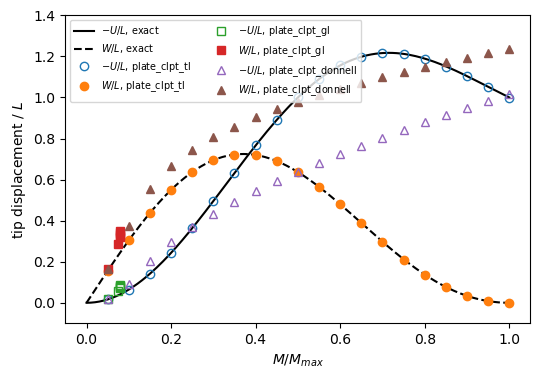

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
Ms = np.linspace(1e-6, 1., 200)
Ue, We = np.array([em.inextensible_arc(f*em.M_MAX) for f in Ms]).T
ax.plot(Ms, -Ue/em.L, 'k-', label='$-U/L$, exact')
ax.plot(Ms, We/em.L, 'k--', label='$W/L$, exact')
styles = {'plate_clpt_tl': 'o', 'plate_clpt_gl': 's', 'plate_clpt_donnell': '^'}
for model, path in paths.items():
    f = np.array(sorted(path))
    U, W = np.array([path[k] for k in f]).T
    ax.plot(f, -U/em.L, styles[model], mfc='none', label='$-U/L$, ' + model)
    ax.plot(f, W/em.L, styles[model], label='$W/L$, ' + model)
ax.set_xlabel('$M/M_{max}$')
ax.set_ylabel('tip displacement / $L$')
ax.set_ylim(-0.1, 1.4)
ax.legend(fontsize=7, ncol=2)
plt.show()

## 2. Wing box under a follower tip force

The High-AR-t5 wing box of Elalfy et al.: half-span 1010.0 mm, chord 50.5 mm, height 12.12 mm, 9 bays, skins and ribs of 1.0 mm, spars of 5.0 mm, aluminium ($E$ = 73 GPa, $\nu$ = 0.33), clamped at the root. Each bay has an upper and a lower skin, two spars and a rib, 45 plate domains in total, connected with penalties: `'BFycte'`/`'BFxcte'` between the skins and the spars or ribs, `'SSxcte'` between the bays (`wingbox` of the test module `tests/multidomain/test_wingbox_plate_clpt_gl.py`).

The tip force is applied as a pressure on a strip of 10 mm of the upper skin at the tip. As a follower load (`follower='quadratic'`) it remains normal to the deformed skin, like the force of the reference; as a dead load (`follower=False`) it keeps its direction. The path is followed by the Newton-Raphson method in increments of 25 N up to 500 N. The tip displacement is the mean $z$-displacement of the tip edge of the upper skin.

The Abaqus values are those of Fig. 6 (follower force) and Fig. 5 (dead force), p. 10 of the reference, read from the vector paths of the figures, with a reading accuracy of about 1 mm.

In [6]:
P = 500.
loads = np.array(sorted(wb.ABAQUS_FIG6))
ABAQUS_FIG5 = dict(zip(loads, (23.0, 92.4, 184.8, 281.1, 369.0, 443.8)))


def wingbox_path(model, follower):
    md, top = wb.wingbox(model, P, follower)
    t0 = time.time()
    an = Analysis(md.calc_fext, md.calc_fint, md.calc_kC, md.calc_kG)
    an.initialInc = an.maxInc = 0.05
    an.minInc = 1.e-4
    an.static(NLgeom=True, silent=True)
    elapsed = time.time() - t0
    lam = np.asarray(an.increments)
    w = {}
    for Pi in loads:
        k = int(np.argmin(np.abs(lam*P - Pi)))
        if np.isclose(lam[k]*P, Pi):
            w[Pi] = 1e3*wb.tip_w(md, top, an.cs[k])
    print('%-20s follower=%-9s %d DOF, %2d increments, last load %.0f N, %.0f s'
          % (model, follower, md.get_size(), len(lam), lam[-1]*P, elapsed))
    return w


md, top = wb.wingbox('plate_clpt_gl', 25., False)
an = Analysis(md.calc_fext, md.calc_fint, md.calc_kC, md.calc_kG)
an.static(NLgeom=False, silent=True)
w_linear_25 = 1e3*wb.tip_w(md, top, an.cs[0])
print('linear static solution at 25 N: %.2f mm' % w_linear_25)

box = {}
for model in ('plate_clpt_gl', 'plate_clpt_tl', 'plate_clpt_donnell'):
    box[model, 'follower'] = wingbox_path(model, 'quadratic')
box['plate_clpt_gl', 'dead'] = wingbox_path('plate_clpt_gl', False)

linear static solution at 25 N: 22.68 mm


plate_clpt_gl        follower=quadratic 6264 DOF, 20 increments, last load 500 N, 161 s


plate_clpt_tl        follower=quadratic 6264 DOF, 20 increments, last load 500 N, 230 s


plate_clpt_donnell   follower=quadratic 6264 DOF, 20 increments, last load 500 N, 124 s


plate_clpt_gl        follower=False     6264 DOF, 23 increments, last load 500 N, 159 s


Tip $z$-displacement in mm under the follower force, with the relative difference to Abaqus, $(\text{panels} - \text{Abaqus})/\text{Abaqus}$. The linear solution is proportional to the load.

In [7]:
def table(ref, cases):
    header = ['tip force (N)', 'Abaqus', 'linear', 'diff (%)']
    for name in cases:
        header += [name, 'diff (%)']
    rows = []
    for Pi in loads:
        lin = w_linear_25*Pi/25.
        row = [Pi, ref[Pi], lin, 100*(lin/ref[Pi] - 1)]
        for w in cases.values():
            v = w.get(Pi, np.nan)
            row += [v, 100*(v/ref[Pi] - 1)]
        rows.append(row)
    show_table(header, rows, fmt='%.2f')


table(wb.ABAQUS_FIG6, {m: box[m, 'follower'] for m in ('plate_clpt_gl', 'plate_clpt_tl', 'plate_clpt_donnell')})

| tip force (N) | Abaqus | linear | diff (%) | plate_clpt_gl | diff (%) | plate_clpt_tl | diff (%) | plate_clpt_donnell | diff (%) |
|---|---|---|---|---|---|---|---|---|---|
| 25.00 | 23.30 | 22.68 | -2.68 | 22.68 | -2.68 | 22.68 | -2.68 | 13.93 | -40.22 |
| 100.00 | 93.20 | 90.70 | -2.68 | 90.84 | -2.53 | 90.84 | -2.54 | 27.96 | -70.00 |
| 200.00 | 189.60 | 181.41 | -4.32 | 184.37 | -2.76 | 184.32 | -2.79 | 37.72 | -80.10 |
| 300.00 | 298.90 | 272.11 | -8.96 | 287.24 | -3.90 | 286.16 | -4.26 | 44.57 | -85.09 |
| 400.00 | 410.00 | 362.82 | -11.51 | 393.59 | -4.00 | 388.84 | -5.16 | 50.03 | -87.80 |
| 500.00 | 515.50 | 453.52 | -12.02 | 499.83 | -3.04 | 488.73 | -5.19 | 54.65 | -89.40 |

Under the dead tip force, against Fig. 5 of the reference:

In [8]:
table(ABAQUS_FIG5, {'plate_clpt_gl': box['plate_clpt_gl', 'dead']})

| tip force (N) | Abaqus | linear | diff (%) | plate_clpt_gl | diff (%) |
|---|---|---|---|---|---|
| 25.00 | 23.00 | 22.68 | -1.41 | 22.66 | -1.48 |
| 100.00 | 92.40 | 90.70 | -1.84 | 90.23 | -2.35 |
| 200.00 | 184.80 | 181.41 | -1.84 | 179.69 | -2.77 |
| 300.00 | 281.10 | 272.11 | -3.20 | 270.70 | -3.70 |
| 400.00 | 369.00 | 362.82 | -1.68 | 354.57 | -3.91 |
| 500.00 | 443.80 | 453.52 | 2.19 | 428.30 | -3.49 |

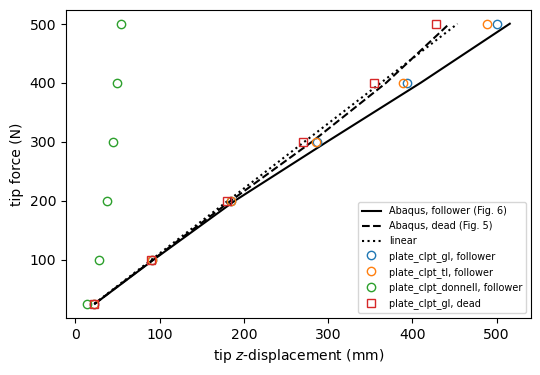

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(list(wb.ABAQUS_FIG6.values()), loads, 'k-', label='Abaqus, follower (Fig. 6)')
ax.plot(list(ABAQUS_FIG5.values()), loads, 'k--', label='Abaqus, dead (Fig. 5)')
ax.plot(w_linear_25*loads/25., loads, 'k:', label='linear')
for (model, kind), w in box.items():
    Pw = sorted(w)
    ax.plot([w[k] for k in Pw], Pw, 'o' if kind == 'follower' else 's', mfc='none',
            label='%s, %s' % (model, kind))
ax.set_xlabel('tip $z$-displacement (mm)')
ax.set_ylabel('tip force (N)')
ax.legend(fontsize=7)
plt.show()

## Discussion

- **Strip.** `'plate_clpt_tl'` rolls the strip into the full circle. Its difference to the exact solution of the inextensible beam is that of the model, of order $(\kappa h)^2$, not of the Ritz approximation, which reproduces the uniform cylindrical solution of the model's own equations closely; the angle $2\pi$ of the full circle needs polynomials of degree 11 or more along the length. `'plate_clpt_gl'`, whose curvatures are measured in the fixed frame, loses the bending energy of a rotated plate by about $\cos^2\theta$: it is too flexible already at $0.05 M_{max}$ (a tip rotation of 0.31 rad) and its Newton-Raphson analysis stops at a small fraction of $M_{max}$. `'plate_clpt_donnell'`, with membrane strains linear in $u$, never rolls the strip: $W$ keeps growing.
- **Wing box.** Below the first buckling load of the top skin (173.11 N in Abaqus, Table 3 of the reference) the box bends through the membrane strains of the skins and the in-plane bending of the spars, and the Green-Lagrange and total-Lagrangian models agree closely. The difference to Abaqus in this range is that of the linear solution: the panels domains lie at the mid-surfaces and are connected with penalties, and the model is a few per cent stiffer than the S4R shell model of Abaqus. Above the buckling load the top skin buckles between the ribs, here without imperfection, and the box becomes softer than the linear beam, as in Abaqus. `'plate_clpt_tl'` is somewhat stiffer than `'plate_clpt_gl'` there, since its buckles, rotated with the box, keep their bending energy. The von Kármán model `'plate_clpt_donnell'` cannot represent the large rotation of the box.
- **Wing box, `'plate_clpt_gl'` against Abaqus.** The tip deflections of `'plate_clpt_gl'` are 2.5 to 4.0 % below Abaqus from 25 to 500 N. The model is already 2.7 % stiffer than Abaqus in the linear range, which explains most of the difference; the rest comes from the post-buckling of the top skin, here without imperfection and with the default penalties, after the first buckling load of 173.11 N of Abaqus, and from the sagging of both skins towards the mid-plane (Brazier effect), which makes the box softer than the linear beam at 500 N: there the top skin deflects in alternate directions from bay to bay, -2.4 mm in the second bay, and both skins sag towards the mid-plane, the bottom one by 1.4 mm in the root bay, about 11 % of the height $H$; the box is softer than the linear beam, as in Abaqus, whereas the elastica of the linear bending stiffness gives 423.0 mm. The changes of curvature of the skins are measured in the fixed local frames and the rotation penalties of the connections are those of small rotations, both of which act at the order of $1 - \cos t$ of the local rotation $t$.